In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
orders = pd.read_csv("../data/olist_orders_dataset.csv")
items = pd.read_csv("../data/olist_order_items_dataset.csv")

In [3]:
print(orders.shape)
print(items.shape)

(99441, 8)
(112650, 7)


In [4]:
merged = items.merge(orders, on="order_id")
print(merged.shape)

(112650, 14)


In [5]:
delivered = merged[merged["order_status"] == "delivered"]
print(delivered.shape)


(110197, 14)


In [6]:
delivered["order_purchase_timestamp"] = pd.to_datetime(delivered["order_purchase_timestamp"])
delivered["order_purchase_timestamp"].dtype


dtype('<M8[us]')

In [7]:
delivered["month"] = delivered["order_purchase_timestamp"].dt.strftime('%Y-%m')
delivered["month"].head()

0    2017-09
1    2017-04
2    2018-01
3    2018-08
4    2017-02
Name: month, dtype: str

In [8]:
delivered["revenue"] = delivered["price"] + delivered["freight_value"]
delivered["revenue"].head()

0     72.19
1    259.83
2    216.87
3     25.78
4    218.04
Name: revenue, dtype: float64

In [9]:
monthly = delivered.groupby("month")["revenue"].sum()
print(monthly.shape)
monthly.head()

(23,)


month
2016-09       143.46
2016-10     46490.66
2016-12        19.62
2017-01    127482.37
2017-02    271239.32
Name: revenue, dtype: float64

In [10]:
growth = (monthly - monthly.shift(1)) / monthly.shift(1)
growth.head()


month
2016-09            NaN
2016-10     323.067057
2016-12      -0.999578
2017-01    6496.572375
2017-02       1.127661
Name: revenue, dtype: float64

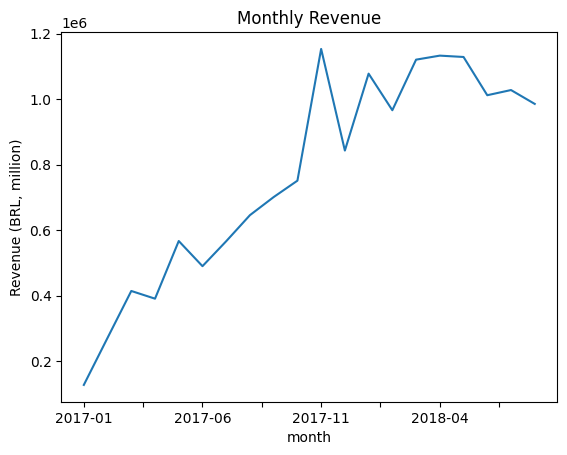

In [11]:
trend = monthly.loc["2017-01":]
trend.plot()
plt.title("Monthly Revenue")
plt.ylabel("Revenue (BRL, million)")
plt.show()


**Finding:**

the data has an uptrend starting at January 2017 which is around 127,482 (BRL), climbing up to its peak on November 2017 which hit around 1.15M (BRL) which is about 9 times of January revenue, it is likely driven by Black Friday month. It stabilizes between 0.97M (BRL) and 1.13M (BRL) per month until August 2018.